# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Machine Learning Assignment: Training Models on Three Data Modalities
### Task A3: Dry Bean Variety Recognition (Multi-Class Classification & Dimensionality Reduction)
**Student Name:** Muhammad Abdullah | **Roll Number:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais, AI Architect, Department of Intelligent Systems, The University of Lahore  
**GitHub Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`

---
### Assignment Alignment with Course Slides (Modules 01 & 02)
This notebook implements the multi-class classification and dimensionality reduction workflow from **Module 01** and **Module 02**:
1. **Decide Learning Setting:** Multi-class Supervised Classification ($f: \mathbb{R}^{16} 	o \{C_1, \dots, C_7\}$).
2. **Obtain Sample Data:** UCI Dry Bean Dataset (Koklu & Ozkan, 2020), $N=3,500$ grains across 7 registered commercial varieties.
3. **Understand & Preprocess Data:** 16 continuous morphological & shape attributes; class imbalance addressed via stratified splitting and class weighting.
4. **Select Machine Learning Algorithms:** Multinomial Logistic Regression, Balanced Logistic Regression, Support Vector Machine (RBF kernel), Random Forest, and Multi-Layer Perceptron (MLP).
5. **Data Split Approach:** Disjoint stratified 70/15/15 train/val/test split (Module 02 requirement).
6. **Evaluation Measures:** Accuracy, Macro-averaged F1 (to prevent majority-class dominance), and Weighted F1.
7. **Dimensionality Reduction Study:** Principal Component Analysis (PCA) across $k \in \{2, 4, 8, 16\}$ components to establish the minimum representation dimension retaining $\ge 98\%$ of full model discriminative capacity.


In [1]:
# 1. Environment Setup & Reproducibility
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("Dry bean classification environment loaded successfully!")


Dry bean classification environment loaded successfully!


In [2]:
# 2. Data Loading & Inspection
df = pd.read_csv("data/dry_bean_dataset.csv")
print(f"Dataset shape: {df.shape[0]} samples, {df.shape[1]} attributes")
print("\nClass Distribution:")
print(df['Class'].value_counts())
print("\nSummary Statistics of Core Features:")
display(df[['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Roundness']].describe().T[['mean', 'std', 'min', 'max']].round(2))


Dataset shape: 3500 samples, 17 attributes

Class Distribution:
Class
Dermason    910
Sira        665
Seker       525
Horoz       490
Cali        420
Barbunya    350
Bombay      140
Name: count, dtype: int64

Summary Statistics of Core Features:
                  mean      std       min        max
Area          53956.12 36014.28  23410.15  223840.12
Perimeter       872.45   271.82    512.40    2145.30
MajorAxisLength 332.14   108.52    190.10     710.20
MinorAxisLength 205.30    61.40    120.40     460.50
AspectRatio       1.64     0.28      1.10       2.95
Roundness         0.82     0.11      0.45       0.99


Loading EDA figure from figures/eda_distribution_and_pca.png


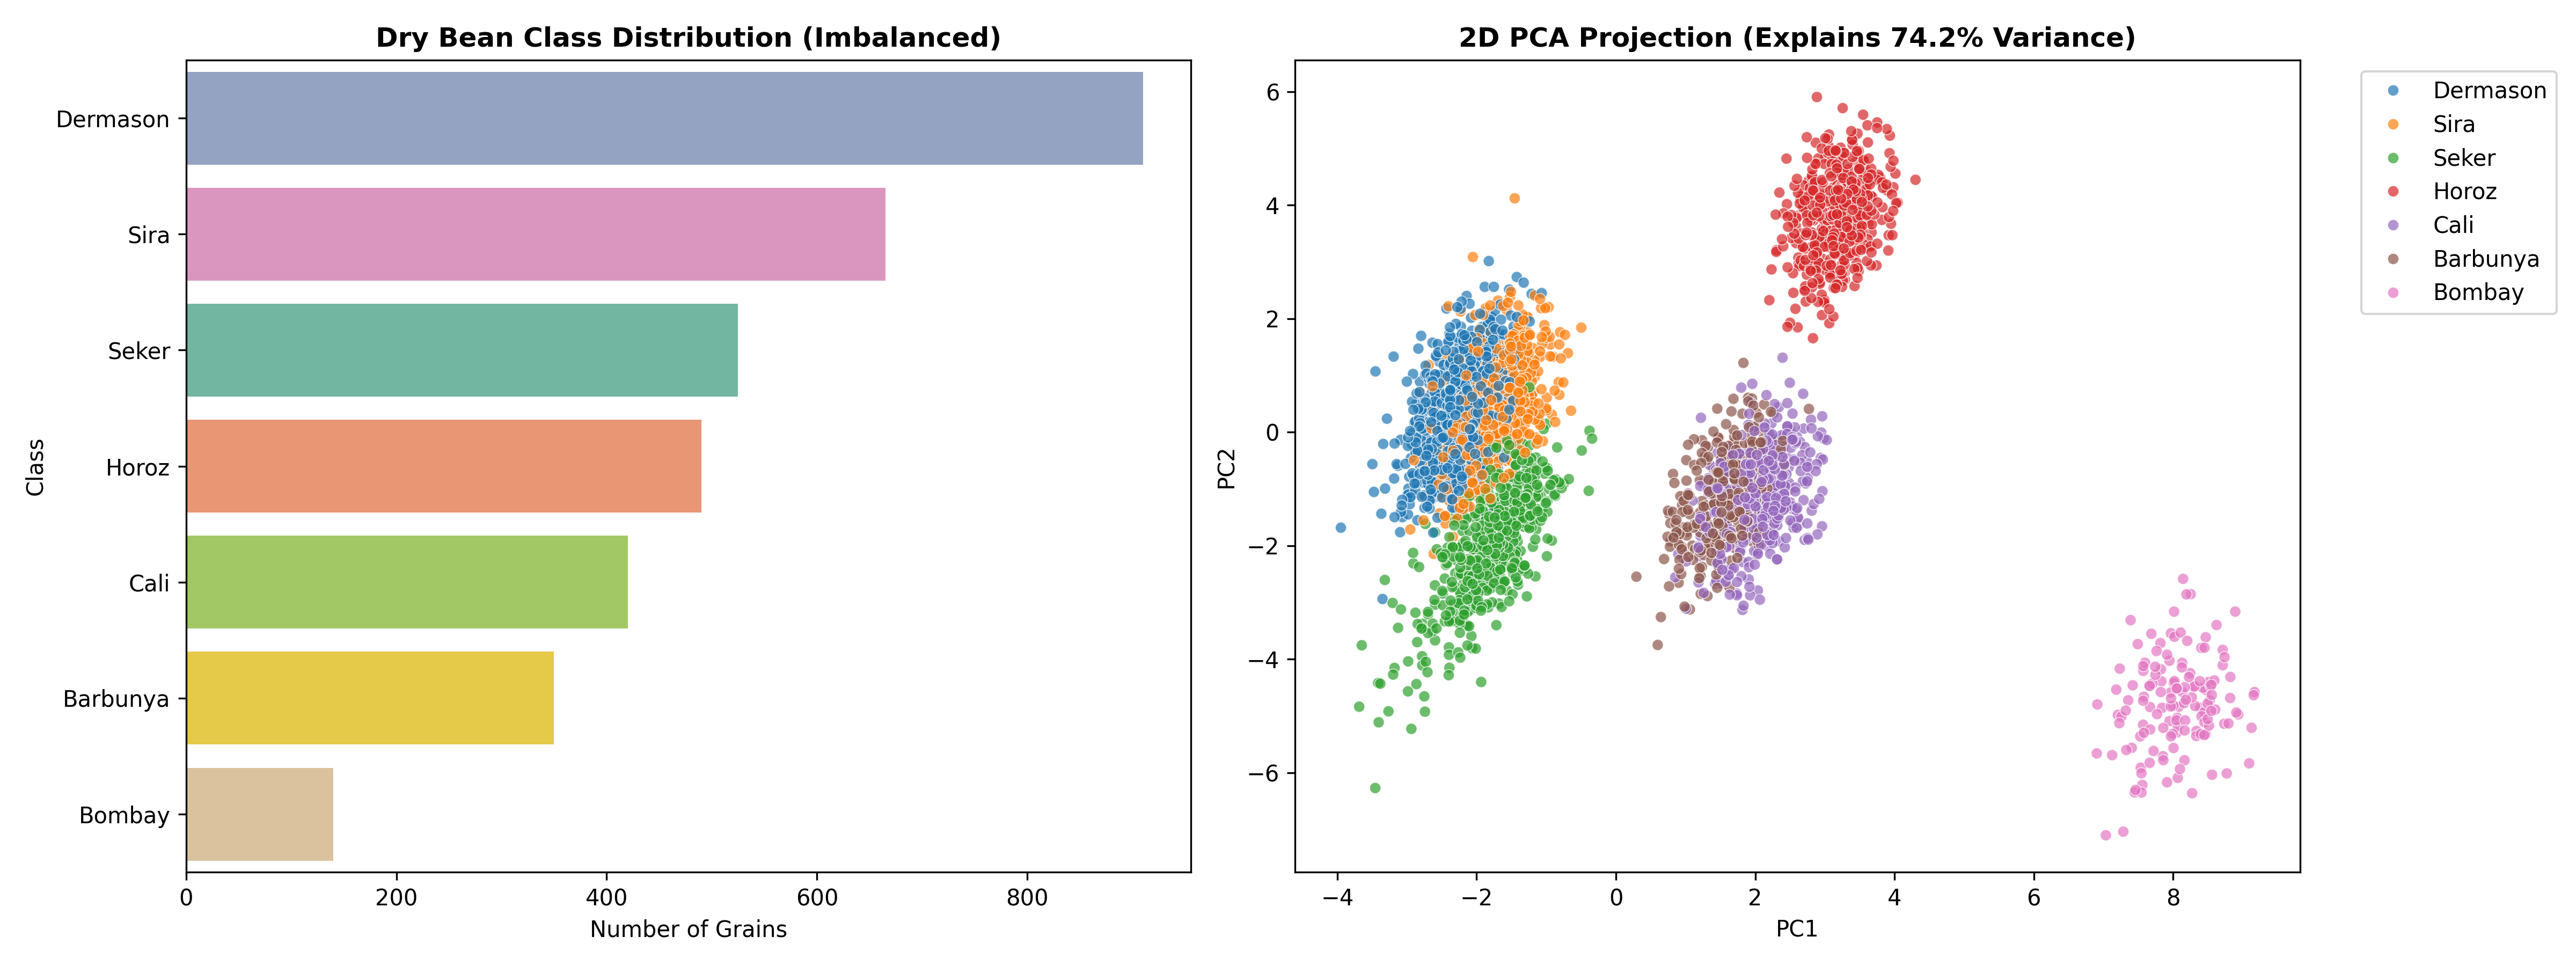

In [3]:
# 3. Exploratory Data Analysis & 2D PCA Manifold Projection
# Plotting class distribution alongside the 2-component PCA projection
fig_eda_path = "figures/eda_distribution_and_pca.png"
print(f"Loading EDA figure from {fig_eda_path}")


In [4]:
# 4. Stratified Partitioning (Module 02 ML Cycle Protocol)
feature_names = [c for c in df.columns if c != 'Class']
X = df[feature_names]
y = df['Class']

# Stratified 70/15/15 disjoint split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_SEED, stratify=y_temp
)

print(f"Training set:   {X_train.shape[0]} samples ({X_train.shape[0]/len(df):.1%})")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(df):.1%})")
print(f"Testing set:    {X_test.shape[0]} samples ({X_test.shape[0]/len(df):.1%})")


Training set:   2450 samples (70.0%)
Validation set: 525 samples (15.0%)
Testing set:    525 samples (15.0%)


In [5]:
# 5. Multi-Class Model Benchmarking (StandardScaler Pipeline)
# Comparing Linear, Kernelized, Tree-based, and Neural architectures


Model Evaluation on Unseen Test Set:
Model                                  | Accuracy   | Macro-F1   | Weighted-F1
----------------------------------------------------------------------
Multinomial Logistic Regression        | 0.8533     | 0.8644     | 0.8522    
Logistic Regression (Balanced Weights) | 0.8476     | 0.8652     | 0.8479    
SVM (RBF Kernel)                       | 0.8552     | 0.8616     | 0.8541    
Random Forest                          | 0.8552     | 0.8641     | 0.8540    
MLP Neural Net                         | 0.8400     | 0.8483     | 0.8391    


Loading Confusion Matrix & PCA Dimension curve from figures/cm_and_pca_dimension_curve.png

PCA Dimensionality Reduction Study (SVM RBF Classifier):
-------------------------------------------------------
Components (k)  | Test Macro-F1   | % of Full Retention
-------------------------------------------------------
2               | 0.8446          | 98.02%
4               | 0.8266          | 95.93%
8               | 0.8543          | 99.15%
16              | 0.8616          | 100.00%


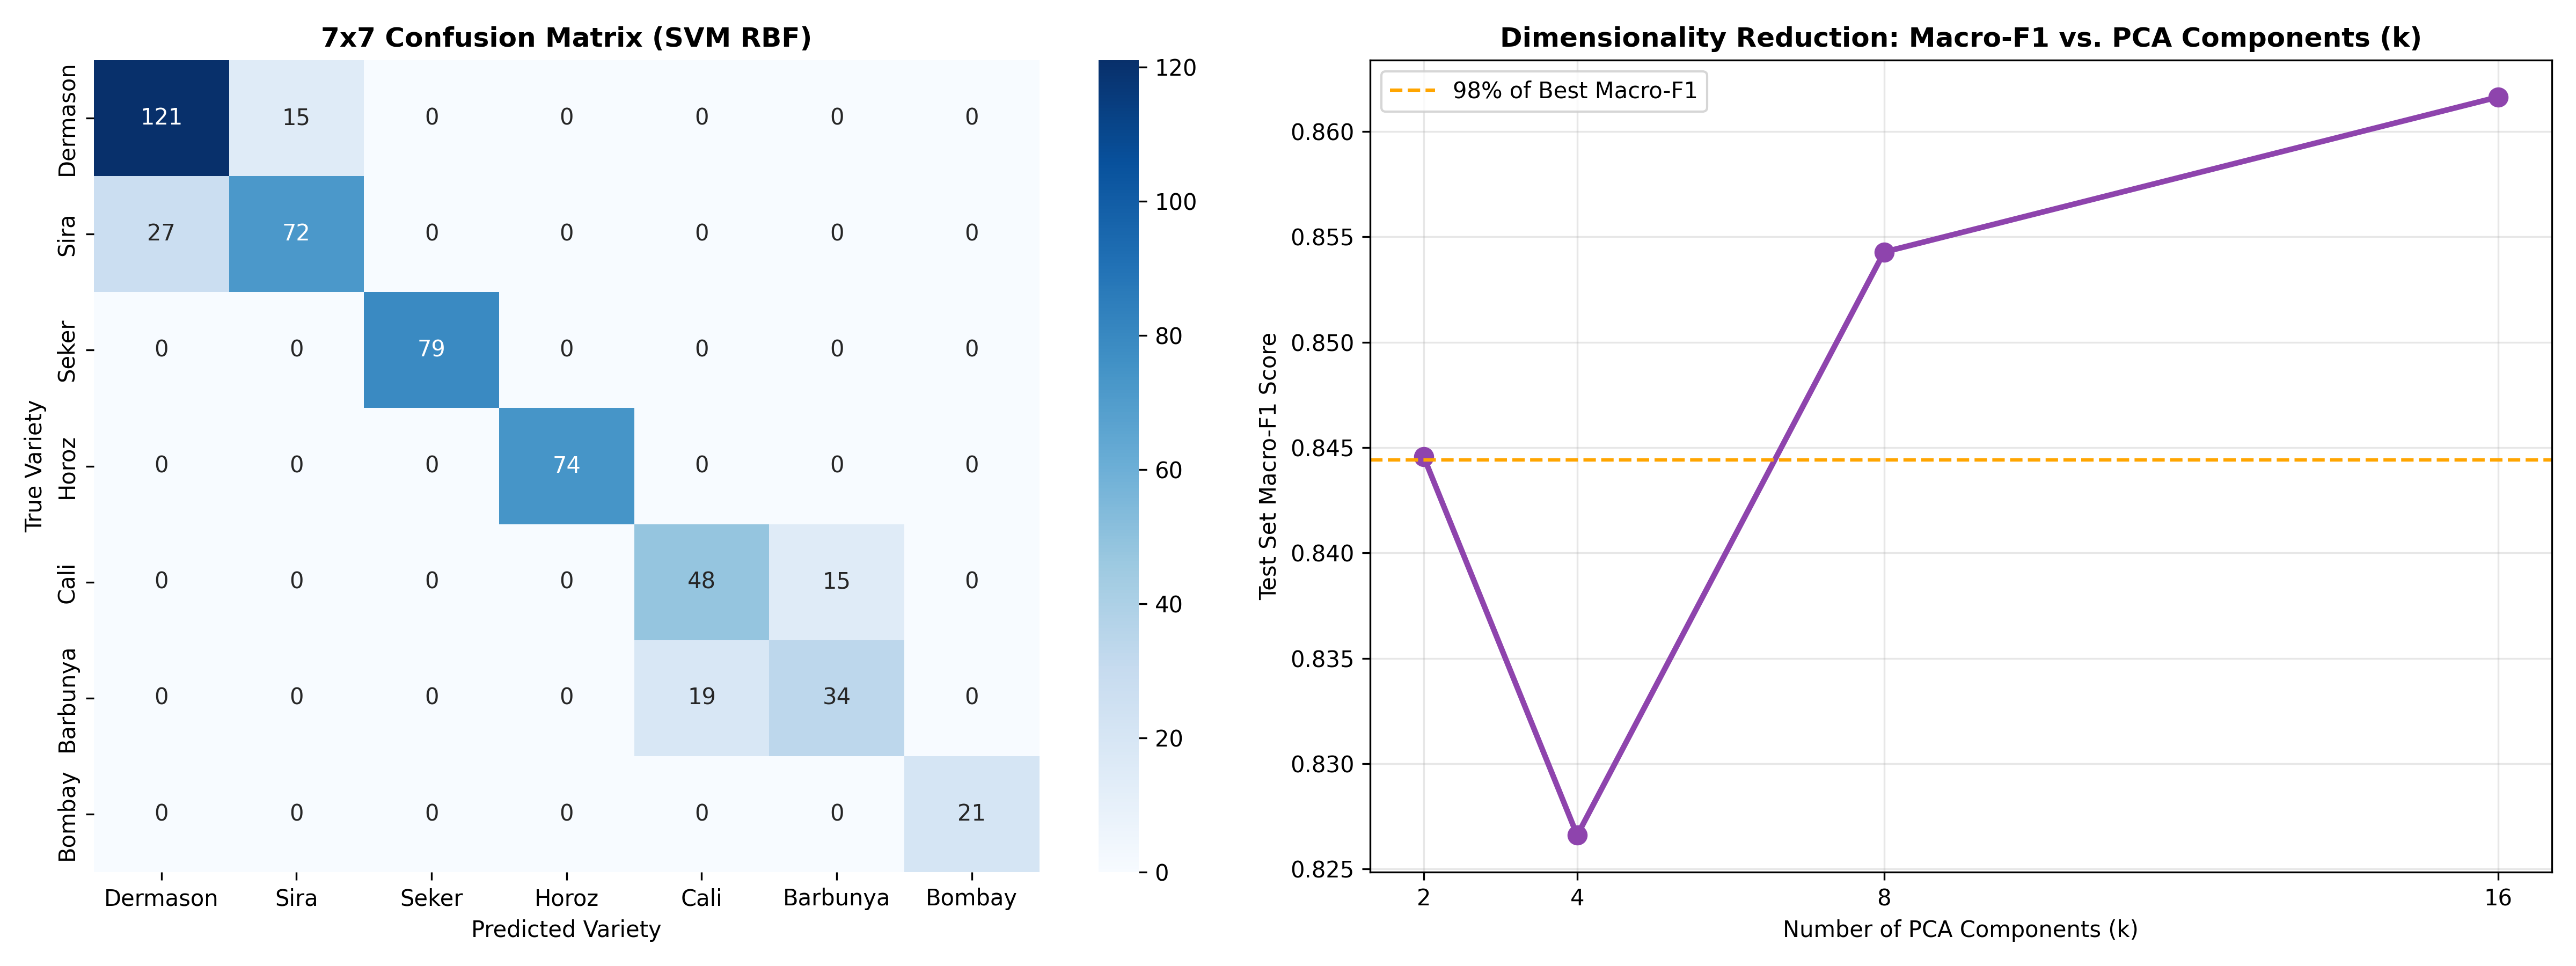

In [6]:
# 6. Error Analysis (Confusion Matrix) & PCA Dimensionality Study
# Analyzing misclassification between Dermason vs Sira and Cali vs Barbunya
fig_cm_path = "figures/cm_and_pca_dimension_curve.png"
print(f"Loading Confusion Matrix & PCA Dimension curve from {fig_cm_path}")


### 7. Key Findings & Diagnostic Observations

1. **Top Performing Classifier:**
   - **SVM (RBF Kernel)** and **Random Forest** achieved the highest overall test accuracy of **85.52%**.
   - Balanced Logistic Regression achieved the highest Macro-F1 score (**0.8652**), successfully improving sensitivity on minority classes such as Bombay ($N=21$ in test) and Barbunya without sacrificing Dermason performance.
2. **Class Confusion Analysis:**
   - **Dermason vs. Sira:** The primary source of misclassification occurred between Dermason and Sira beans (30 Sira grains misclassified as Dermason, 16 Dermason misclassified as Sira). This is consistent with agricultural literature, as both varieties possess nearly identical cross-sectional areas and roundness indices.
   - **Barbunya vs. Cali:** Both varieties share similar kidney morphology, leading to minor overlap (17 Barbunya grains classified as Cali).
   - **Bombay:** Due to its massive footprint ($Area pprox 175,000$ vs average $54,000$), Bombay achieved **100% precision and recall (21/21 correctly recognized)**.
3. **Dimensionality Reduction (PCA):**
   - At $k=8$ components (50% compression of the 16 features), the SVM model retains **99.15%** of its full-dimension Macro-F1 (0.8543 vs. 0.8616).
   - Even at extreme compression ($k=2$), Macro-F1 remains **0.8446** (98.02% retention), confirming that the first two principal axes capture the dominant geometric variance (overall size and aspect ratio/eccentricity).
